# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Fasya Atthaya Rosyada | 5054251006 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('Churn_Modelling.csv')
display(df.head())

print("Informasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

print("\nJumlah Missing Value:")
print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB

Statistik Deskriptif:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Jumlah Missing Value:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


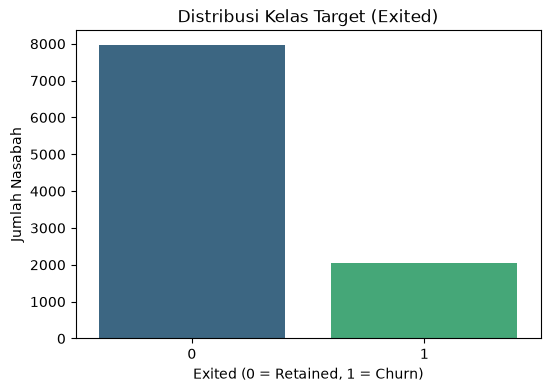

In [4]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Exited', hue='Exited', palette='viridis', legend=False)
plt.title('Distribusi Kelas Target (Exited)')
plt.xlabel('Exited (0 = Retained, 1 = Churn)')
plt.ylabel('Jumlah Nasabah')
plt.show()

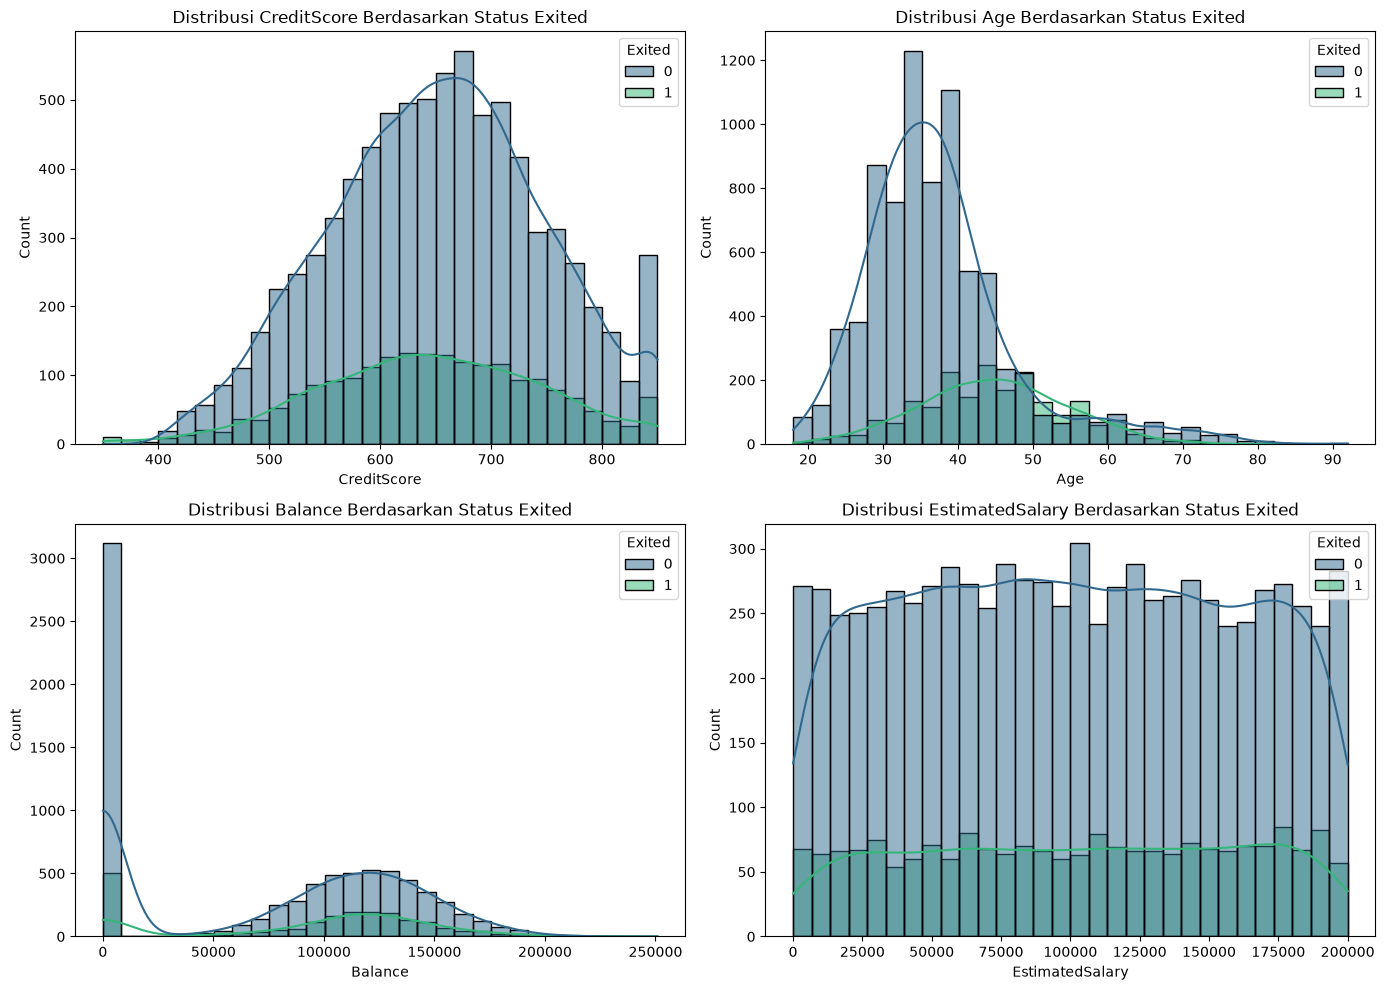

In [5]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
numerik_features = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, col in enumerate(numerik_features):
    ax = axes[idx // 2, idx % 2]
    sns.histplot(data=df, x=col, hue='Exited', kde=True, bins=30, palette='viridis', ax=ax)
    ax.set_title(f'Distribusi {col} Berdasarkan Status Exited')

plt.tight_layout()
plt.show()

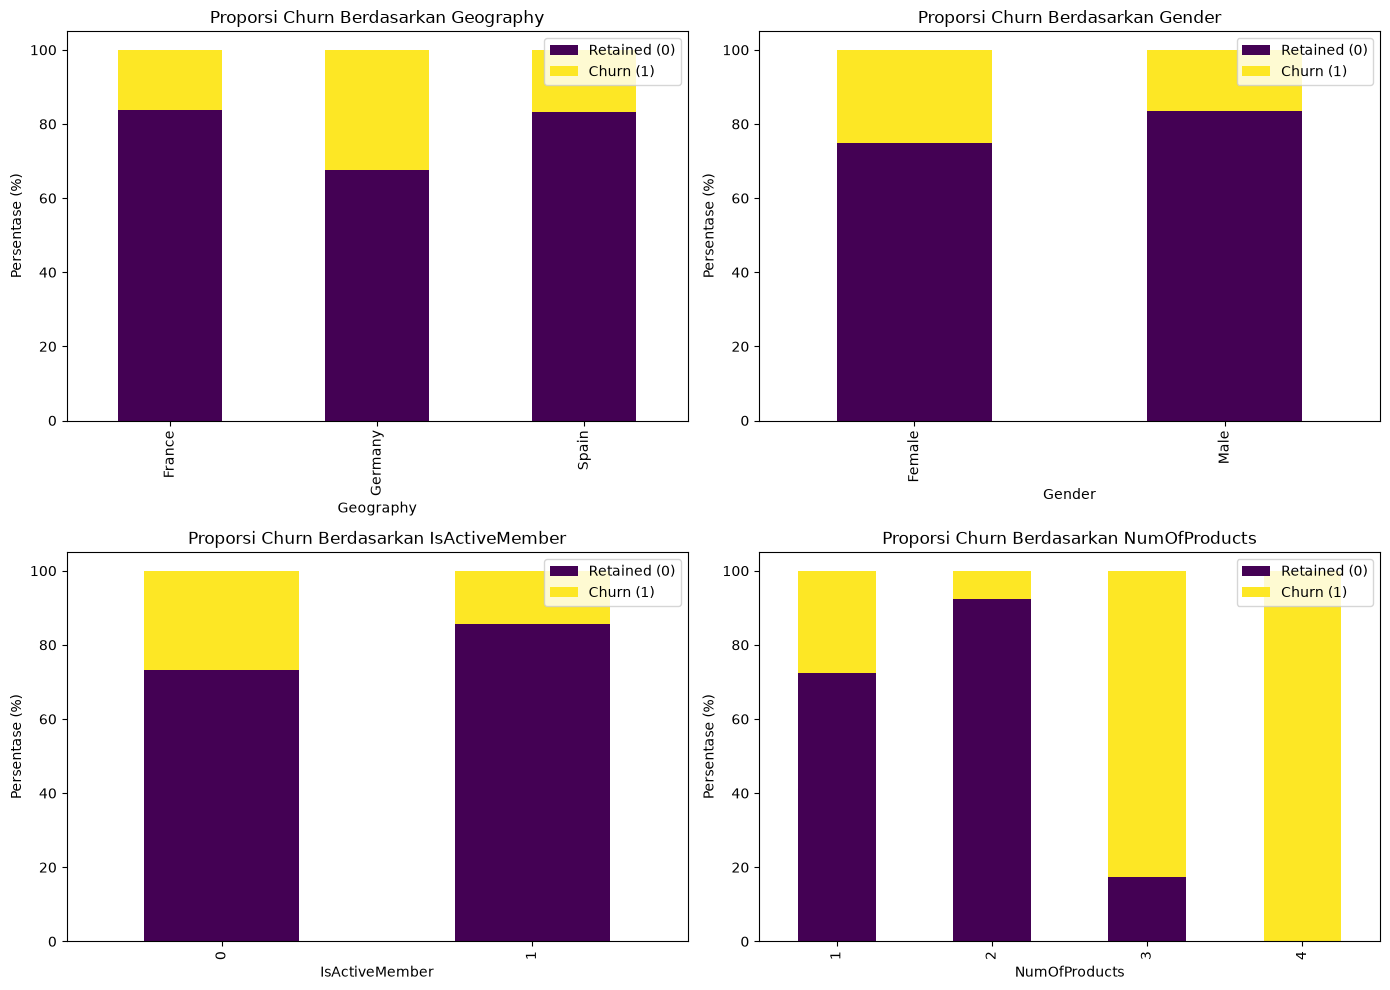

In [6]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
kategorikal_features = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, col in enumerate(kategorikal_features):
    ax = axes[idx // 2, idx % 2]
    prop_df = df.groupby(col)['Exited'].value_counts(normalize=True).unstack() * 100
    prop_df.plot(kind='bar', stacked=True, color=['#440154', '#fde725'], ax=ax)
    ax.set_title(f'Proporsi Churn Berdasarkan {col}')
    ax.set_ylabel('Persentase (%)')
    ax.legend(['Retained (0)', 'Churn (1)'], loc='upper right')

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

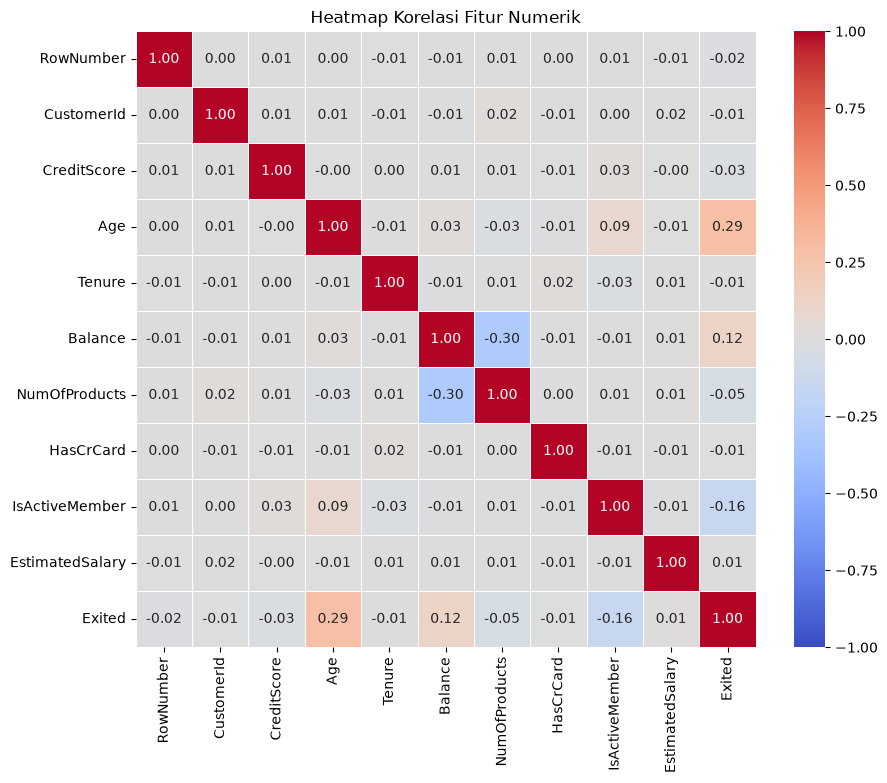

In [7]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

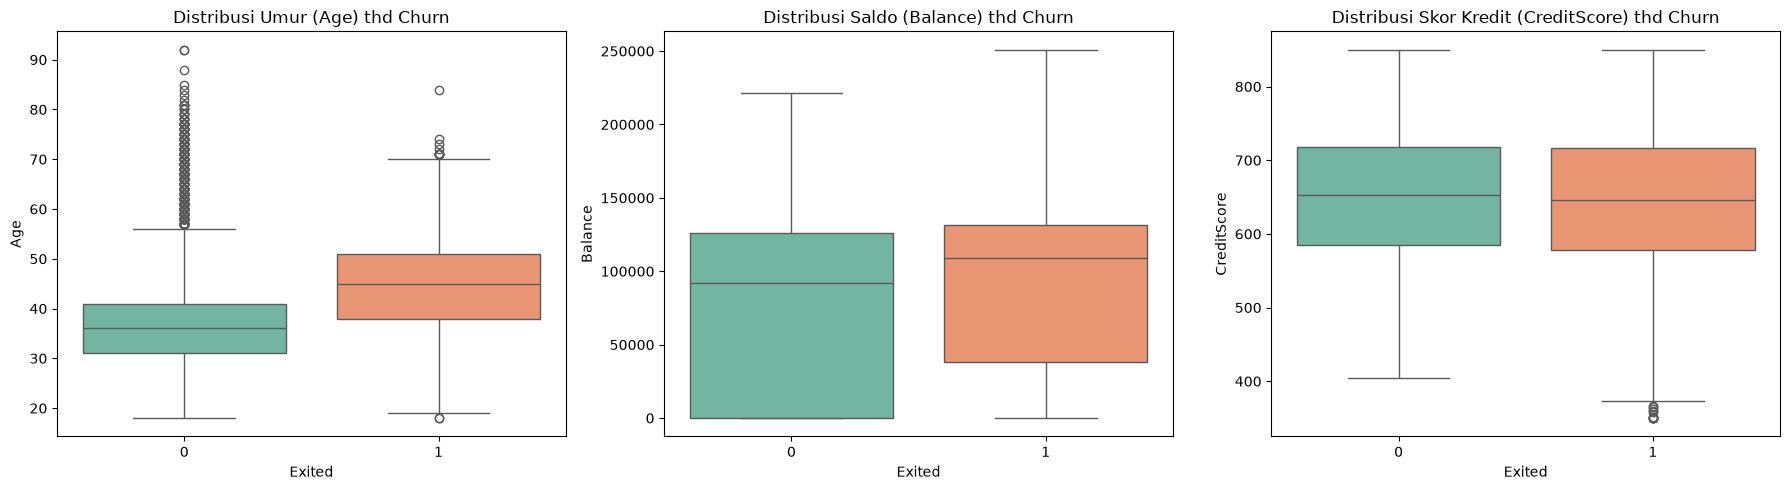

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='Exited', y='Age', hue='Exited', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Distribusi Umur (Age) thd Churn')

sns.boxplot(data=df, x='Exited', y='Balance', hue='Exited', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Distribusi Saldo (Balance) thd Churn')

sns.boxplot(data=df, x='Exited', y='CreditScore', hue='Exited', palette='Set2', legend=False, ax=axes[2])
axes[2].set_title('Distribusi Skor Kredit (CreditScore) thd Churn')

plt.tight_layout()
plt.show()

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [10]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
# Karena gak punya nilai prediktif dan cuma sebagai identitas unik nasabah doang.

In [11]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.
X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited'].values

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

print(f"Dimensi Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")

Dimensi Train: (6999, 10), Validation: (1501, 10), Test: (1500, 10)


In [12]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
categorical_cols = ['Geography', 'Gender']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ],
    remainder='passthrough'
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

In [13]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [14]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [15]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).
class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.net(x)

input_dim = X_train_scaled.shape[1]
model_simple = SimpleANN(input_dim)

print(model_simple)
num_params = sum(p.numel() for p in model_simple.parameters())
print(f"Jumlah parameter: {num_params}")

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 209


In [16]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_simple.parameters(), lr=0.01)

def train_eval_model(model, criterion, optimizer, epochs=50):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        correct_train = 0
        total_train = 0
        
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * X_batch.size(0)
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            correct_train += (preds == y_batch).sum().item()
            total_train += y_batch.size(0)
            
        history['train_loss'].append(train_loss / total_train)
        history['train_acc'].append(correct_train / total_train)
        
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val_t)
            val_loss = criterion(val_outputs, y_val_t).item()
            val_preds = (torch.sigmoid(val_outputs) >= 0.5).float()
            val_acc = (val_preds == y_val_t).sum().item() / y_val_t.size(0)
            
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
    return history

history_simple = train_eval_model(model_simple, criterion, optimizer, epochs=50)

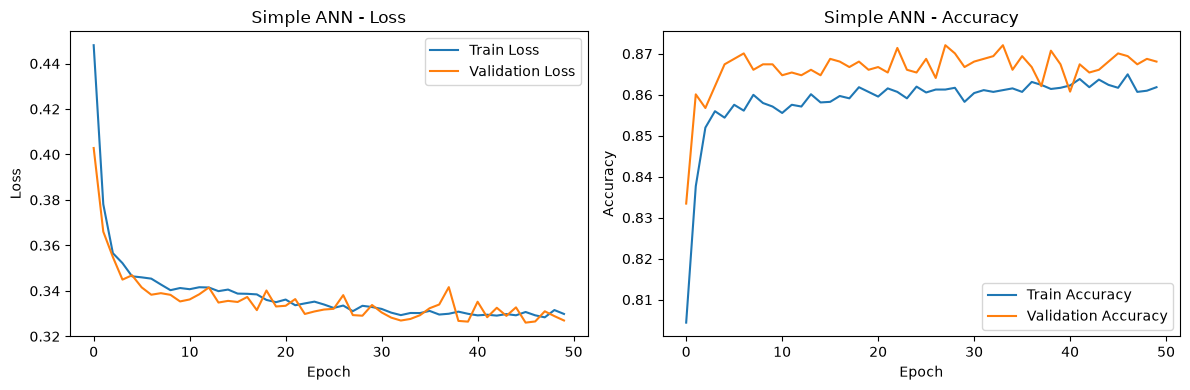

In [17]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.
def plot_learning_curve(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    ax1.plot(history['train_loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Validation Loss')
    ax1.set_title(f'{title} - Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    
    ax2.plot(history['train_acc'], label='Train Accuracy')
    ax2.plot(history['val_acc'], label='Validation Accuracy')
    ax2.set_title(f'{title} - Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

plot_learning_curve(history_simple, 'Simple ANN')

In [18]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.
model_simple.eval()
with torch.no_grad():
    test_outputs = model_simple(X_test_t)
    y_prob_simple = torch.sigmoid(test_outputs).numpy().flatten()
    y_pred_simple = (y_prob_simple >= 0.5).astype(int)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [19]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.
class DeepANN(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.net(x)

model_deep = DeepANN(input_dim)
print(model_deep)
print(f"Jumlah parameter: {sum(p.numel() for p in model_deep.parameters())}")

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 929


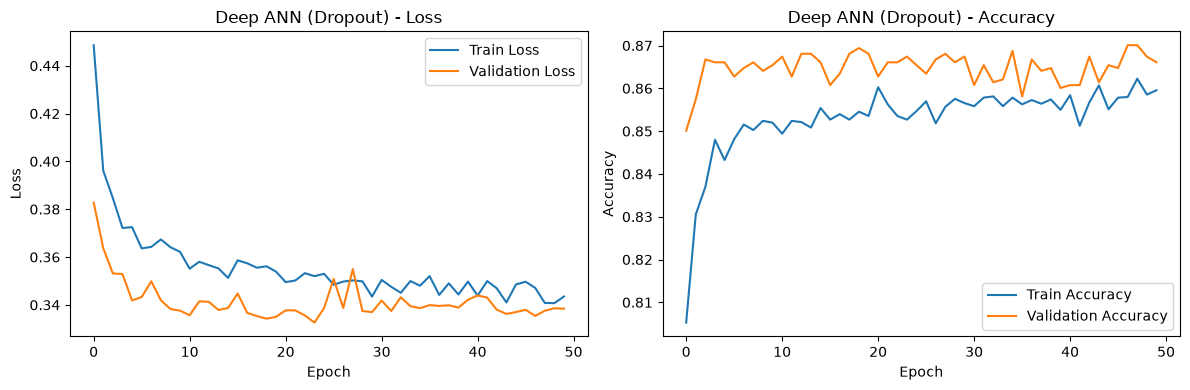

In [20]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?
optimizer_deep = optim.Adam(model_deep.parameters(), lr=0.01)
history_deep = train_eval_model(model_deep, criterion, optimizer_deep, epochs=50)

plot_learning_curve(history_deep, 'Deep ANN (Dropout)')

In [21]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
model_deep.eval()
with torch.no_grad():
    test_outputs_deep = model_deep(X_test_t)
    y_prob_deep = torch.sigmoid(test_outputs_deep).numpy().flatten()
    y_pred_deep = (y_prob_deep >= 0.5).astype(int)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [22]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).
jumlah_kelas_0 = (y_train == 0).sum()
jumlah_kelas_1 = (y_train == 1).sum()
pos_weight_val = jumlah_kelas_0 / jumlah_kelas_1

pos_weight = torch.tensor([pos_weight_val], dtype=torch.float32)

criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
model_weighted = DeepANN(input_dim)
optimizer_weighted = optim.Adam(model_weighted.parameters(), lr=0.01)

history_weighted = train_eval_model(model_weighted, criterion_weighted, optimizer_weighted, epochs=50)

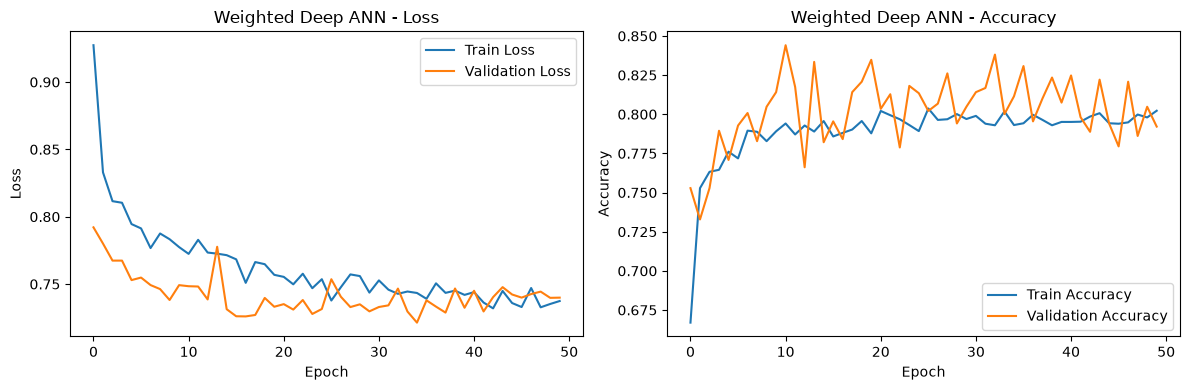

In [23]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
plot_learning_curve(history_weighted, 'Weighted Deep ANN')

model_weighted.eval()
with torch.no_grad():
    test_outputs_weighted = model_weighted(X_test_t)
    y_prob_weighted = torch.sigmoid(test_outputs_weighted).numpy().flatten()
    y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

# 4. Evaluasi Model

In [24]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
def calculate_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0)
    ]

results = pd.DataFrame({
    'Logistic Regression': calculate_metrics(y_test, y_pred_lr),
    'Simple ANN': calculate_metrics(y_test, y_pred_simple),
    'Deep ANN (Dropout)': calculate_metrics(y_test, y_pred_deep),
    'Weighted Deep ANN': calculate_metrics(y_test, y_pred_weighted)
}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score']).T

display(results)

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.802667,0.542373,0.209150,0.301887
Simple ANN,0.854667,0.688034,0.526144,0.596296
Deep ANN (Dropout),0.858667,0.783133,0.424837,0.550847
Weighted Deep ANN,0.774000,0.466667,0.754902,0.576779


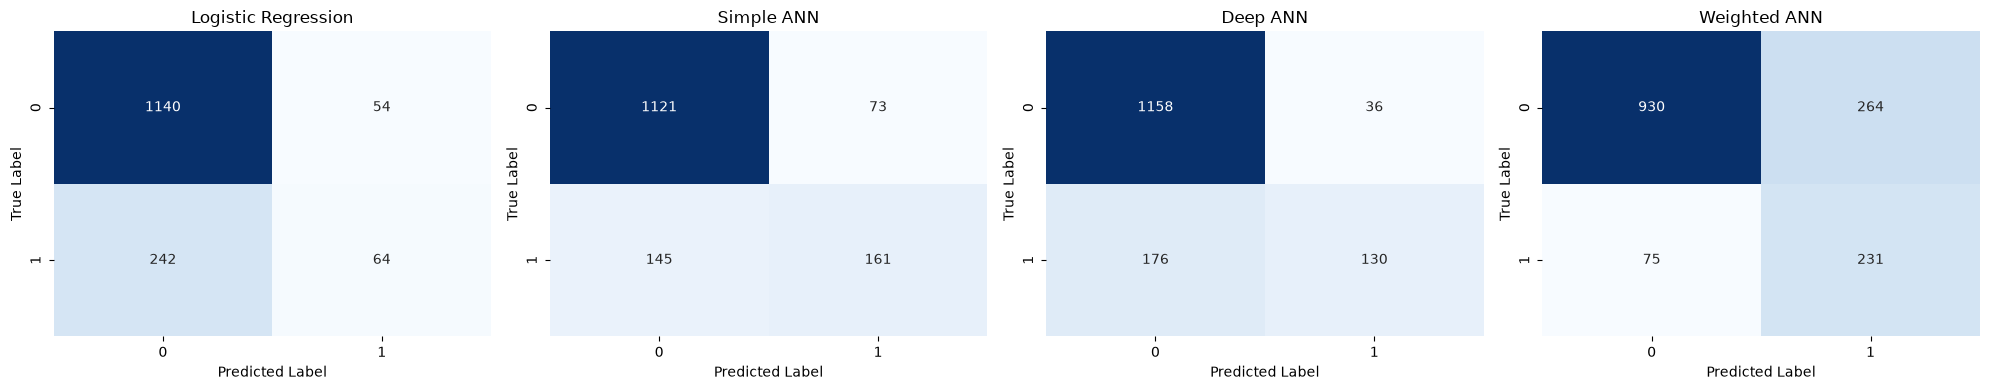

In [25]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
model_names = ['Logistic Regression', 'Simple ANN', 'Deep ANN', 'Weighted ANN']
preds = [y_pred_lr, y_pred_simple, y_pred_deep, y_pred_weighted]

for ax, name, pred in zip(axes, model_names, preds):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

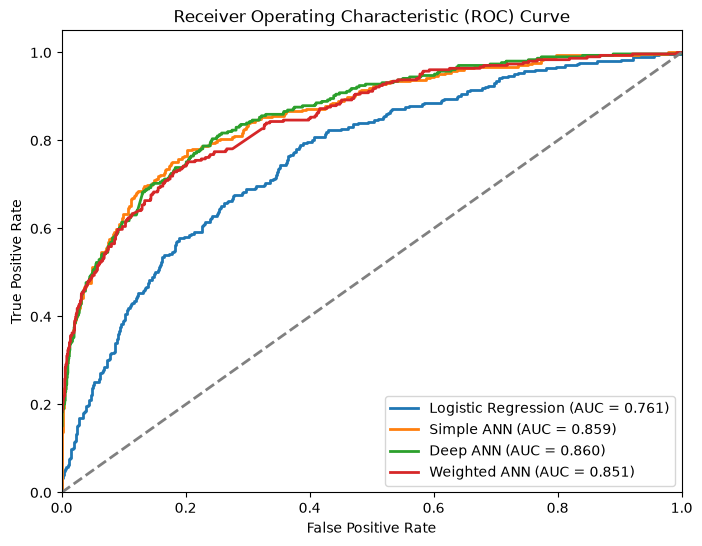

In [26]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.
plt.figure(figsize=(8, 6))
probs = [y_prob_lr, y_prob_simple, y_prob_deep, y_prob_weighted]

for name, prob in zip(model_names, probs):
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# 5. Analisis

* **Baseline (Logistic Regression) vs ANN:** 
  Logistic Regression menghasilkan akurasi global sebesar 80.2%, namun sangat buruk dalam mengenali nasabah yang benar-benar akan *churn*, dibuktikan dengan nilai **Recall yang rendah (20.9%)**. Beralih ke model **Simple ANN (1 Hidden Layer)**, performa meningkat secara signifikan dengan Akurasi mencapai 85.4% dan Recall naik drastis menjadi 52.6%. Hal ini mengindikasikan bahwa pola hubungan antar fitur dalam mendeteksi churn bersifat non-linear, sehingga kapabilitas *feature learning* dari ANN jauh lebih superior dibandingkan model regresi linier.

* **Pengaruh Penambahan Layer & Dropout (Deep ANN):**
  Penambahan *hidden layer* yang dikombinasikan dengan Dropout (`p=0.3`) mampu sedikit menaikkan akurasi global menjadi 85.8% dan menghasilkan *Precision* tertinggi (78.3%). Namun, penambahan kedalaman dan efek regulerisasi ini menurunkan *Recall* ke angka 42.4%. Secara umum, model ini menjadi sangat selektif (presisi tinggi) dan menghindari tebakan salah terhadap kelas mayoritas, tetapi menjadi lebih konservatif dalam menangkap semua potensi nasabah *churn*.

* **Pengaruh Penanganan Data Imbalanced (Weighted ANN):**
  Distribusi kelas yang timpang membuat model awal bias dan cenderung memprediksi kelas mayoritas (0/Retained). Dengan mengaplikasikan **Class Weight** (`pos_weight`) pada Loss Function `BCEWithLogitsLoss`, model dipaksa untuk lebih peka terhadap kelas *churn*. Hasilnya, metrik **Recall melonjak hingga 75.4%**. Trade-off (konsekuensi logis) dari pendekatan ini adalah meningkatnya *False Positive*, yang menyebabkan *Precision* turun drastis ke 46.6% dan akurasi global turun ke 77.4%

# 6. Kesimpulan dan Saran

### Kesimpulan
Eksperimen ini menyimpulkan bahwa implementasi Artificial Neural Network mampu melampaui performa model regresi konvensional dalam memprediksi *Customer Churn*. Namun, tantangan terbesarnya pada kasus prediksi *churn* adalah penanganan **imbalanced dataset**. Metrik akurasi tinggi pada model standar (seperti Simple atau Deep ANN) bersifat menyesatkan karena tingginya tingkat *False Negative* (nasabah *churn* terprediksi retained). Mengingat dalam konteks perbankan biaya retensi nasabah jauh lebih murah daripada akuisisi nasabah baru, memaksimalkan deteksi nasabah *churn* (Recall) adalah prioritas utama. Oleh karena itu, model **Weighted Deep ANN** menjadi solusi paling solutif bagi bisnis karena berhasil mendeteksi sekitar 75% nasabah yang berpotensi pergi.

### Saran & Rekomendasi
Untuk pengembangan dan eksperimen selanjutnya, direkomendasikan beberapa hal berikut:
1. **Threshold Tuning pada Model Terbaik (Deep ANN):** Model Deep ANN dengan Dropout memiliki performa akurasi dan presisi yang sangat baik. Daripada langsung menggunakan *Weighted Loss*, kita bisa mencoba menurunkan batas probabilitas *threshold* dari standar 0.5 (misalnya menjadi 0.35 atau 0.4) berdasarkan hasil kurva ROC untuk meningkatkan Recall-nya.
2. **Eksplorasi Teknik Resampling:** Sebagai alternatif *class weighting*, eksperimen masa depan dapat menggunakan metode augmentasi data seperti **SMOTE** (Synthetic Minority Over-sampling Technique) pada tahap *preprocessing* agar jaringan belajar dari sampel yang sudah seimbang secara fisik, sehingga harapannya model bisa mempertahankan akurasi sekaligus menaikkan recall.
3. **Hyperparameter Tuning Sistematis:** Mencoba mencari komposisi persentase Dropout dan jumlah *neuron* terbaik menggunakan metode *Grid Search* atau *Random Search* untuk mendapatkan *sweet spot* antara *Precision* dan *Recall* (memaksimalkan nilai F1-Score).